# Abalone: exploratory data analysis
We predict **Rings**, a shell-ring count used as an age proxy, not age in years.
Sex is categorical; the seven physical measurements are numerical features.
We check the full file for schema and basic quality, then explore only the training
partition. Validation and test targets are reserved for modelling and evaluation.

In [1]:
import hashlib
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

plt.style.use("default")
pd.set_option("display.max_columns", 20)

## 1. Load and validate

In [2]:
ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "abalone.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place abalone.csv in the project's data directory.")
DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
EXPECTED_COLUMNS = [
    "Sex",
    "Length",
    "Diameter",
    "Height",
    "Whole weight",
    "Shucked weight",
    "Viscera weight",
    "Shell weight",
    "Rings",
]
assert list(df.columns) == EXPECTED_COLUMNS, "Unexpected dataset columns"
assert df["Rings"].notna().all(), "The target must not contain missing values"
assert df["Rings"].gt(0).all(), "Ring counts must be positive"
assert set(df["Sex"].dropna().unique()).issubset({"M", "F", "I"})
print(f"Rows: {len(df):,}; columns: {len(df.columns)}")
print(f"Data SHA-256: {DATA_SHA256}")

Rows: 4,177; columns: 9
Data SHA-256: 6fda3c4b0c0cff9bd5f7a46434509179069ed620c8fc7090d872a08d2c1a729a


In [3]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
    }
)
display(quality)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Non-positive heights:", int(df["Height"].le(0).sum()))

,dtype,missing
Sex,object,0
Length,float64,0
Diameter,float64,0
Height,float64,0
Whole weight,float64,0
Shucked weight,float64,0
Viscera weight,float64,0
Shell weight,float64,0
Rings,int64,0


Exact duplicate rows: 0
Non-positive heights: 2


## 2. Freeze the split
Use a fixed seed and approximately 60% training, 20% validation, 20% test.
Do not delete rows using thresholds learned from validation/test data. Keep valid
extreme values; they may be genuine older animals. Missing numerical values will
be imputed inside a fitted pipeline.

In [4]:
SEED = 42
X = df.drop(columns="Rings").copy()
y = df["Rings"].copy()
# Zero height is not a plausible physical measurement. Treat it as missing;
# each pipeline learns its replacement median from training data only.
X.loc[X["Height"] <= 0, "Height"] = np.nan
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
print(f"Train: {len(X_train)}, validation: {len(X_val)}, test: {len(X_test)}")

Train: 2505, validation: 836, test: 836


In [5]:
train_df = X_train.assign(Rings=y_train)
display(train_df.describe(include="all"))

,Sex,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
count,2505,2505.000000,2505.000000,2503.000000,2505.000000,2505.000000,2505.000000,2505.000000,2505.000000
unique,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,918,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,0.525551,0.409108,0.139495,0.831285,0.360364,0.180742,0.240110,9.992415
std,NaN,0.118348,0.098029,0.038001,0.488393,0.220045,0.108342,0.139279,3.220644
min,NaN,0.075000,0.055000,0.010000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,NaN,0.450000,0.350000,0.115000,0.446500,0.188500,0.093000,0.130000,8.000000
50%,NaN,0.545000,0.425000,0.145000,0.805000,0.339500,0.171000,0.235000,10.000000
75%,NaN,0.615000,0.480000,0.165000,1.154000,0.500500,0.252500,0.330000,11.000000


## 3. Training distributions

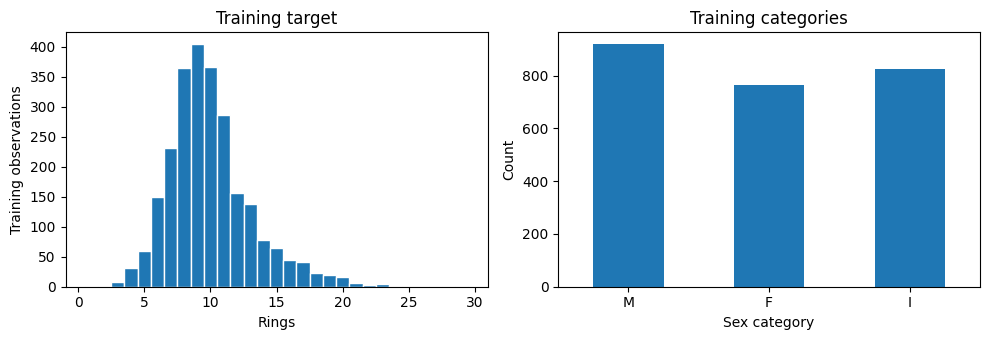

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(y_train, bins=np.arange(0.5, y_train.max() + 1.5), edgecolor="white")
axes[0].set(xlabel="Rings", ylabel="Training observations", title="Training target")
train_df["Sex"].value_counts().reindex(["M", "F", "I"]).plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel="Sex category", ylabel="Count", title="Training categories")
plt.tight_layout()
plt.show()

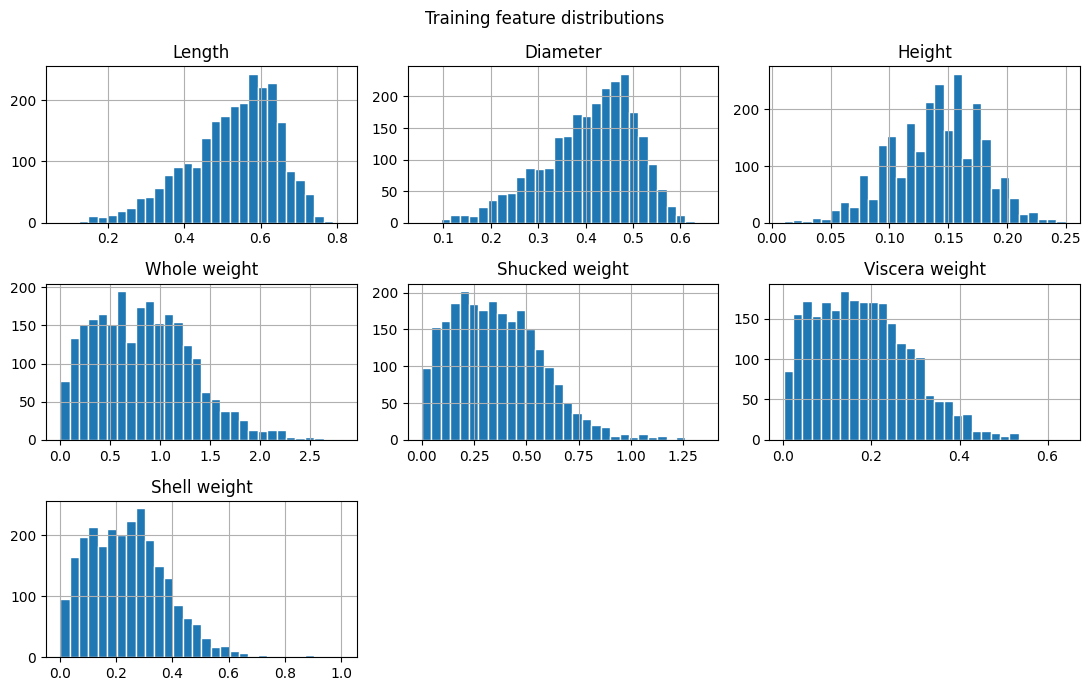

In [7]:
numeric_columns = X_train.select_dtypes(include="number").columns.tolist()
train_df[numeric_columns].hist(bins=30, figsize=(11, 7), edgecolor="white")
plt.suptitle("Training feature distributions")
plt.tight_layout()
plt.show()

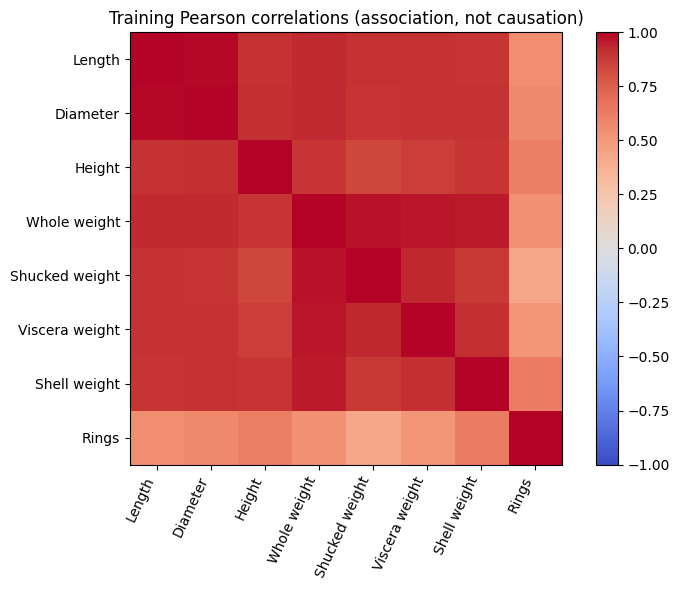

,Rings
Shell weight,0.630026
Height,0.619805
Diameter,0.570381
Length,0.552142
Whole weight,0.542416
Viscera weight,0.512985
Shucked weight,0.423210


In [8]:
correlation = train_df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=65, ha="right")
ax.set_yticks(range(len(correlation)), correlation.columns)
ax.set_title("Training Pearson correlations (association, not causation)")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()
display(correlation["Rings"].drop("Rings").sort_values(ascending=False).to_frame())

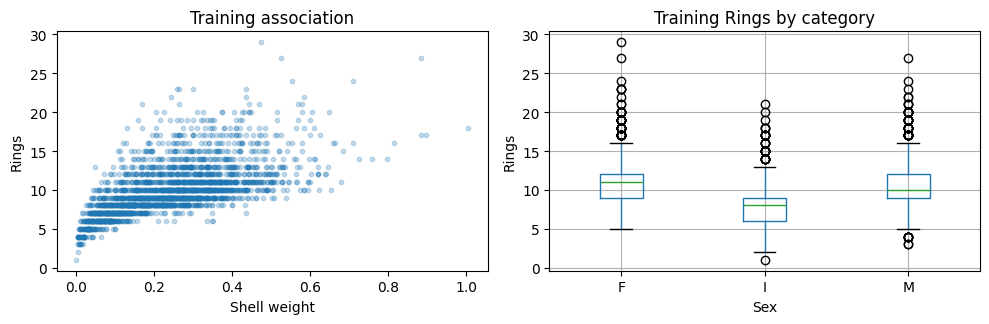

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(X_train["Shell weight"], y_train, alpha=0.25, s=10)
axes[0].set(xlabel="Shell weight", ylabel="Rings", title="Training association")
train_df.boxplot(column="Rings", by="Sex", ax=axes[1])
axes[1].set(title="Training Rings by category", ylabel="Rings")
fig.suptitle("")
plt.tight_layout()
plt.show()

## 4. Conclusions and modelling plan
- The file has 4,177 rows, 9 columns, no missing values and no exact duplicate rows.
- There are two zero-height records; zero heights are treated as missing
  and imputed using training medians, without discarding observations.
- Encode Sex using one-hot encoding; do not impose an artificial numeric order.
- Inspect the training histograms for skew and the correlation table for related
  physical measurements. Correlation alone is not evidence of causation.
- Start with a mean predictor, then linear regression and a fixed random forest.
- Choose the candidate with the lowest validation MAE. Use RMSE as a secondary
  measure sensitive to large errors. MAE/RMSE are measured in **rings**.
- Keep the test set untouched until the candidate is selected. A random split
  measures within-dataset generalization, not performance at a new farm or time.
See modelling.ipynb for the selected model and evaluation results.